# Multi-Armed Bandit

Multi-armed / $k$-armed bandit: exploration–exploitation with stochastic rewards.

## Problem
At each step we choose one of $k$ arms and receive a stochastic reward. Goal: maximize cumulative reward. True means $q^*(a)=\mathbb{E}[R_t \mid A_t=a]$ are unknown.

## Protocol
- $k=10$ arms
- Stationary case: $q^*(a) \sim \mathcal{N}(0,1)$, then $R \sim \mathcal{N}(q^*(a), 1)$
- One run = 1000 pulls (unless stated otherwise); average curves over ~2000 independent runs
- Metrics: **average reward** and **% optimal action** over time

## Methods implemented below
1. $\varepsilon$-greedy
2. Incremental / constant step-size updates
3. Optimistic initialization
4. Non-stationary bandit + constant $\alpha$
5. UCB
6. Gradient bandit


In [1]:
import numpy as np 
import matplotlib.pyplot as plt
np.random.seed(42)

## Environment & agent base classes

**`Bandit`.** Draws true means `q_star` once per run; `pull(a)` returns a noisy reward. `best_arm` is only for evaluation (the agent must not use it to choose).

**`Agent`.** Shared loop: `select_action` → `pull` → `update` (learn $Q$) → `record` (log reward / optimality for plots). Subclasses only change the selection (and sometimes the update).


In [2]:
class Bandit:
    def __init__(self, n_arms=10):
        self.n_arms = n_arms
        self.q_star = np.random.randn(n_arms)
        self.best_arm = np.argmax(self.q_star)
        
    def pull(self, arm):
        return np.random.normal(self.q_star[arm], 1)
    
    

In [3]:
class Agent:

    def __init__(self, bandit, num_actions):
        self.bandit = bandit
        self.num_actions = num_actions
        self.Q = np.zeros(self.num_actions)
        self.N = np.zeros(self.num_actions)

    def run(self, num_steps):
        self.reset()
        for _ in range(num_steps):
            action = self.select_action()
            reward = self.bandit.pull(action)
            self.update(action, reward)
            self.record(action, reward)

    def select_action(self):
        pass

    def record(self, action, reward):
        self.rewards.append(reward)
        self.optimal_actions.append(int(action == self.bandit.best_arm))
        

    def update(self, action, reward):
        self.N[action] += 1
        self.Q[action] += (reward - self.Q[action]) / self.N[action]
    
    def reset(self):
        self.Q = np.zeros(self.num_actions)
        self.N = np.zeros(self.num_actions)
        self.rewards = []
        self.optimal_actions = []


# $\varepsilon$-greedy

**Reminder.** We do not know the true means $q^*(a)$. We keep estimates $Q(a)$ (sample average of rewards) and face the exploration–exploitation trade-off.

**Action choice.**
- with probability $\varepsilon$: pick an arm uniformly at random (explore)
- with probability $1-\varepsilon$: pick $\arg\max_a Q(a)$ (exploit; break ties at random)

**What we do here.** Compare $\varepsilon \in \{0, 0.01, 0.1\}$ on the stationary 10-armed bandit (2000 runs × 1000 steps). Plot average reward and frequency of choosing the optimal arm.


In [4]:
class EpsilonGreedyAgent(Agent):

    def __init__(self, bandit, epsilon):
        super().__init__(bandit, bandit.n_arms)
        self.epsilon = epsilon
    
    def select_action(self):
        if np.random.rand() < self.epsilon:
            return np.random.randint(self.num_actions)
        else:
            return np.random.choice(np.flatnonzero(self.Q == self.Q.max()))

In [5]:
n_runs, n_steps = 2000, 1000  
all_rewards_1 = np.zeros((n_runs, n_steps))
all_rewards_2 = np.zeros((n_runs, n_steps))
all_rewards_3 = np.zeros((n_runs, n_steps))

opt_1 = np.zeros((n_runs, n_steps))
opt_2 = np.zeros((n_runs, n_steps))
opt_3 = np.zeros((n_runs, n_steps))

for run in range(n_runs):
    bandit = Bandit()
    agent_1 = EpsilonGreedyAgent(bandit, 0.1)
    agent_1.run(n_steps)
    all_rewards_1[run] = agent_1.rewards
    opt_1[run] = agent_1.optimal_actions

    agent_2 = EpsilonGreedyAgent(bandit, 0.01)
    agent_2.run(n_steps)
    all_rewards_2[run] = agent_2.rewards
    opt_2[run] = agent_2.optimal_actions
    agent_3 = EpsilonGreedyAgent(bandit, 0)
    agent_3.run(n_steps)
    all_rewards_3[run] = agent_3.rewards
    opt_3[run] = agent_3.optimal_actions



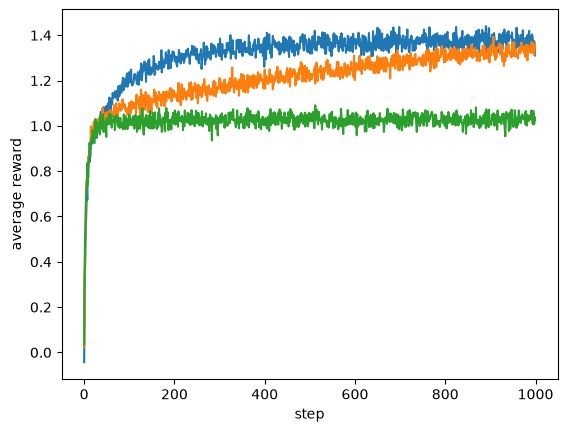

In [6]:
plt.plot(all_rewards_1.mean(axis=0))
plt.plot(all_rewards_2.mean(axis=0))
plt.plot(all_rewards_3.mean(axis=0))
plt.xlabel("step")
plt.ylabel("average reward")
plt.show()

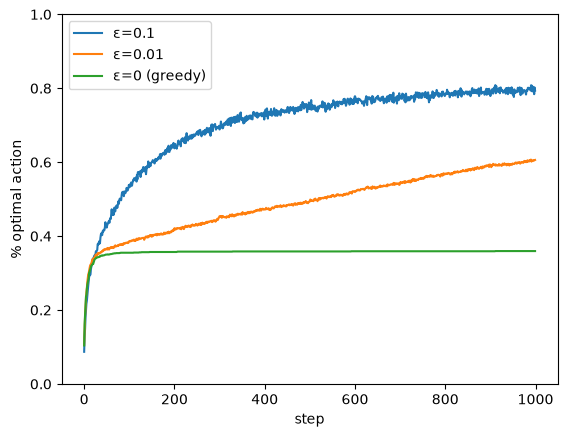

In [7]:
plt.plot(opt_1.mean(axis=0), label="ε=0.1")
plt.plot(opt_2.mean(axis=0), label="ε=0.01")
plt.plot(opt_3.mean(axis=0), label="ε=0 (greedy)")
plt.xlabel("step")
plt.ylabel("% optimal action")
plt.ylim(0, 1)
plt.legend()
plt.show()

# Incremental update

**Reminder.** Recomputing the mean from all past rewards is wasteful. The sample average has an incremental form:

$$Q_{n+1} = Q_n + \frac{1}{n}(R_n - Q_n)$$

More generally: $\text{estimate} \leftarrow \text{estimate} + \alpha \cdot (\text{observation} - \text{estimate})$.

**What we do here.** Same $\varepsilon$-greedy behaviour, but `update` uses a step size: $\alpha = 1/N(a)$ (sample average) or a constant $\alpha$ if provided. Empirically this matches the previous section when $\alpha=1/N$.


In [8]:
class IncrementalUpdateAgent(EpsilonGreedyAgent):

    def __init__(self, bandit, epsilon, alpha=None):
        super().__init__(bandit, epsilon)
        self.alpha = alpha

    def update(self, action, reward):
        self.N[action] += 1

        if self.alpha is None:
            step = 1 / self.N[action]
        else:
            step = self.alpha
        self.Q[action] += step * (reward - self.Q[action])


In [9]:
n_runs, n_steps = 2000, 1000  
all_rewards_1 = np.zeros((n_runs, n_steps))
all_rewards_2 = np.zeros((n_runs, n_steps))
all_rewards_3 = np.zeros((n_runs, n_steps))

opt_1 = np.zeros((n_runs, n_steps))
opt_2 = np.zeros((n_runs, n_steps))
opt_3 = np.zeros((n_runs, n_steps))

for run in range(n_runs):
    bandit = Bandit()
    agent_1 = IncrementalUpdateAgent(bandit, 0.1)
    agent_1.run(n_steps)
    all_rewards_1[run] = agent_1.rewards
    opt_1[run] = agent_1.optimal_actions

    agent_2 = IncrementalUpdateAgent(bandit, 0.01)
    agent_2.run(n_steps)
    all_rewards_2[run] = agent_2.rewards
    opt_2[run] = agent_2.optimal_actions
    
    agent_3 = IncrementalUpdateAgent(bandit, 0)
    agent_3.run(n_steps)
    all_rewards_3[run] = agent_3.rewards
    opt_3[run] = agent_3.optimal_actions


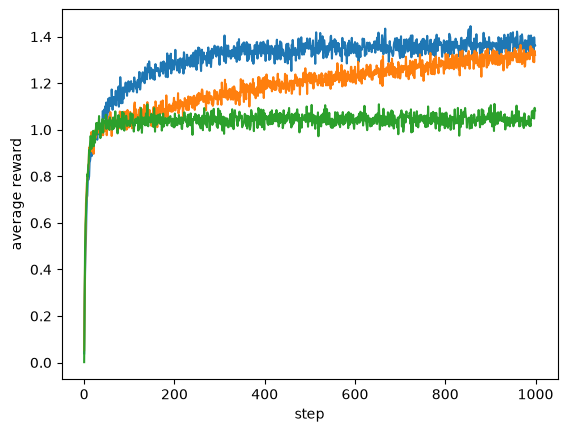

In [10]:
plt.plot(all_rewards_1.mean(axis=0))
plt.plot(all_rewards_2.mean(axis=0))
plt.plot(all_rewards_3.mean(axis=0))
plt.xlabel("step")
plt.ylabel("average reward")
plt.show()

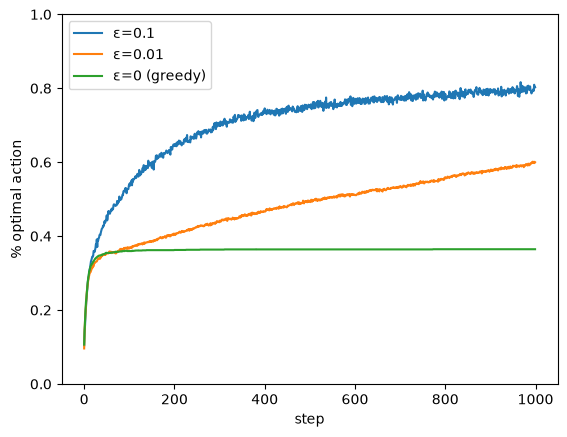

In [11]:
plt.plot(opt_1.mean(axis=0), label="ε=0.1")
plt.plot(opt_2.mean(axis=0), label="ε=0.01")
plt.plot(opt_3.mean(axis=0), label="ε=0 (greedy)")
plt.xlabel("step")
plt.ylabel("% optimal action")
plt.ylim(0, 1)
plt.legend()
plt.show()

# Optimistic initialization

**Reminder.** The initial values $Q_1(a)$ bias early behaviour. Setting them **high** (e.g. $Q_1(a)=5$) makes every arm look good at first, so a greedy agent is forced to try them all. Bad arms’ estimates drop quickly; good arms stay high. This encourages exploration without $\varepsilon$.

**What we do here.** Compare:
- optimistic greedy: $\varepsilon=0$, $Q_0=5$, constant step-size $\alpha=0.1$
- realistic $\varepsilon$-greedy: $\varepsilon=0.1$, $Q_0=0$, $\alpha=0.1$

Optimistic usually rises faster early; $\varepsilon$-greedy may catch up later because it keeps exploring.


In [12]:
class OptimisticInitAgent(IncrementalUpdateAgent):

    def __init__(self, bandit, epsilon, alpha = None, initial_value=5):
        super().__init__(bandit, epsilon, alpha=alpha)
        self.initial_value = initial_value
        self.Q = np.full(self.num_actions, initial_value, dtype=float)
        
    def reset(self):
        self.Q = np.full(self.num_actions, self.initial_value, dtype=float)
        self.N = np.zeros(self.num_actions)
        self.rewards = []
        self.optimal_actions = []


In [13]:
n_runs, n_steps = 2000, 1000  
all_rewards_1 = np.zeros((n_runs, n_steps))
all_rewards_2 = np.zeros((n_runs, n_steps))

opt_1 = np.zeros((n_runs, n_steps))
opt_2 = np.zeros((n_runs, n_steps))

for run in range(n_runs):
    bandit = Bandit()
    agent_1 = OptimisticInitAgent(bandit, epsilon=0.0, alpha = 0.1, initial_value=5.0)
    agent_1.run(n_steps)
    all_rewards_1[run] = agent_1.rewards
    opt_1[run] = agent_1.optimal_actions

    agent_2 = OptimisticInitAgent(bandit, epsilon=0.1, alpha = 0.1, initial_value=0.0)
    agent_2.run(n_steps)
    all_rewards_2[run] = agent_2.rewards
    opt_2[run] = agent_2.optimal_actions

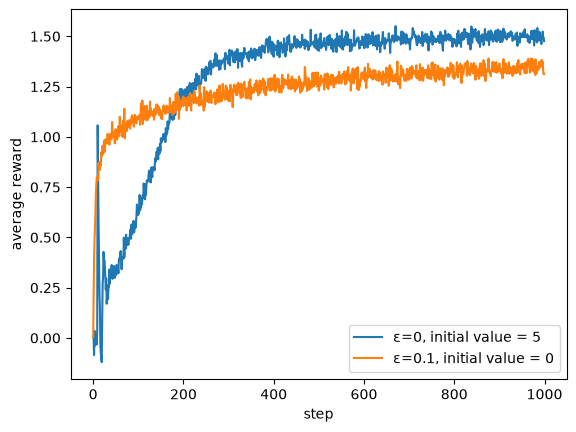

In [14]:
plt.plot(all_rewards_1.mean(axis=0), label="ε=0, initial value = 5")
plt.plot(all_rewards_2.mean(axis=0), label="ε=0.1, initial value = 0")
plt.xlabel("step")
plt.ylabel("average reward")
plt.legend()
plt.show()

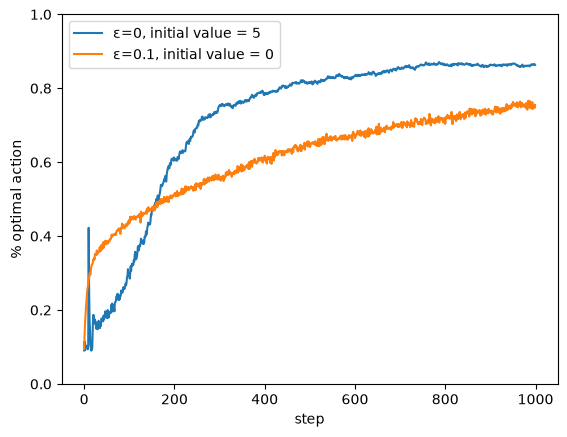

In [15]:
plt.plot(opt_1.mean(axis=0), label="ε=0, initial value = 5")
plt.plot(opt_2.mean(axis=0), label="ε=0.1, initial value = 0")
plt.xlabel("step")
plt.ylabel("% optimal action")
plt.ylim(0, 1)
plt.legend()
plt.show()

# Non-stationary environment & constant step-size

**Reminder.** If the machines’ means $q^*(a)$ change over time, sample averages ($\alpha=1/N$) overweight old data. A **constant** step-size $\alpha \in (0,1]$ gives an exponentially weighted average and adapts better:

$$Q_{n+1} = Q_n + \alpha (R_n - Q_n)$$

**What we do here.**
1. `NonStationaryBandit`: after each pull, every $q^*(a)$ does a small random walk ($\sigma=0.01$).
2. Compare the same $\varepsilon=0.1$ with sample average ($\alpha=1/N$) vs constant $\alpha=0.1$.
3. Use a **fresh** bandit per agent (the environment drifts during a run).
4. Use a **longer horizon** (e.g. 10 000 steps): with only 1000 steps the drift is small and the two curves look almost the same.

**About the plots.** Average reward tends to rise over time because $|q^*|$ grows with the random walk — that is normal. What matters is that constant $\alpha$ stays **above** sample average later. The **% optimal action** plot is often clearer for this comparison.


In [16]:
class NonStationaryBandit():

    def __init__(self, n_arms=10, walk_std=0.01):
        self.n_arms = n_arms
        self.walk_std = walk_std
        self.q_star = np.zeros(n_arms) 
        self.best_arm = np.argmax(self.q_star)

    def pull(self, arm):
        reward = np.random.normal(self.q_star[arm], 1)
        return reward
    
    def step_environment(self):
        self.q_star += np.random.normal(0, self.walk_std, size=self.n_arms)
        self.best_arm = np.argmax(self.q_star)


In [17]:
class IncrementalUpdateAgent2(IncrementalUpdateAgent):

    def __init__(self, bandit, epsilon, alpha=None):
        super().__init__(bandit, epsilon, alpha=alpha)

    def run(self, num_steps):
        self.reset()
        for _ in range(num_steps):
            action = self.select_action()
            reward = self.bandit.pull(action)
            self.update(action, reward)
            self.record(action, reward)
            self.bandit.step_environment()
        

In [18]:
n_runs, n_steps = 2000, 1000  # longer horizon: constant α needs time to pull ahead
all_rewards_1 = np.zeros((n_runs, n_steps))
all_rewards_2 = np.zeros((n_runs, n_steps))

opt_1 = np.zeros((n_runs, n_steps))
opt_2 = np.zeros((n_runs, n_steps))

for run in range(n_runs):
    bandit1 = NonStationaryBandit()
    agent_1 = IncrementalUpdateAgent2(bandit1, epsilon=0.1, alpha=None)
    agent_1.run(n_steps)
    all_rewards_1[run] = agent_1.rewards
    opt_1[run] = agent_1.optimal_actions

    bandit2 = NonStationaryBandit()
    agent_2 = IncrementalUpdateAgent2(bandit2, epsilon=0.1, alpha=0.1)
    agent_2.run(n_steps)
    all_rewards_2[run] = agent_2.rewards
    opt_2[run] = agent_2.optimal_actions


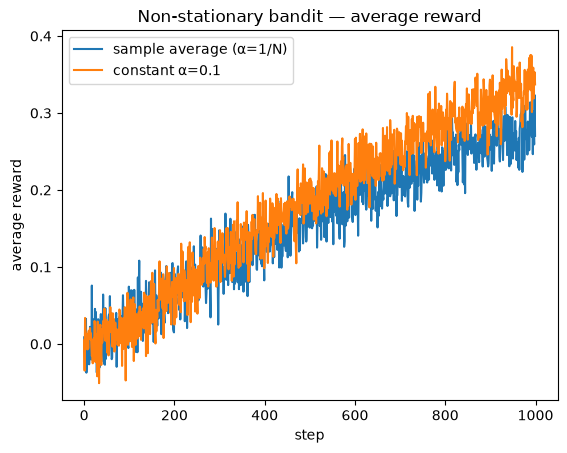

In [19]:
plt.plot(all_rewards_1.mean(axis=0), label="sample average (α=1/N)")
plt.plot(all_rewards_2.mean(axis=0), label="constant α=0.1")
plt.xlabel("step")
plt.ylabel("average reward")
plt.title("Non-stationary bandit — average reward")
plt.legend()
plt.show()


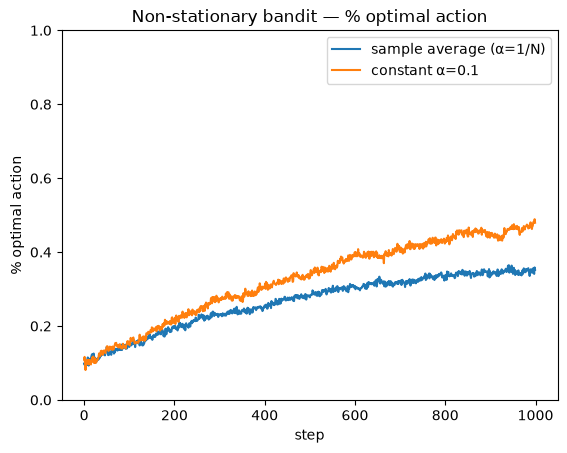

In [20]:
plt.plot(opt_1.mean(axis=0), label="sample average (α=1/N)")
plt.plot(opt_2.mean(axis=0), label="constant α=0.1")
plt.xlabel("step")
plt.ylabel("% optimal action")
plt.title("Non-stationary bandit — % optimal action")
plt.ylim(0, 1)
plt.legend()
plt.show()


# UCB (Upper Confidence Bound)

**Reminder.** $\varepsilon$-greedy explores all non-greedy arms equally. UCB prefers arms that are either promising or uncertain:

$$A_t = \arg\max_a \left[ Q_t(a) + c \sqrt{\frac{\log t}{N_t(a)}} \right]$$

- $N_t(a)$ large $\Rightarrow$ bonus small (well known)
- arm rarely tried $\Rightarrow$ bonus large (worth exploring)
- Play each arm once first (cannot divide by $N=0$).

UCB is a **selection** rule; $Q$ is still updated separately (typically sample average).

**What we do here.** Stationary bandit; compare UCB ($c=2$) to $\varepsilon=0.1$. Plot average reward and % optimal action.


In [21]:
class UCBAgent(Agent):
    def __init__(self, bandit, c=2.0):
        super().__init__(bandit, bandit.n_arms)
        self.c = c

    def select_action(self):
        # play each arm at least once
        unplayed = np.where(self.N == 0)[0]
        if len(unplayed) > 0:
            return np.random.choice(unplayed)

        t = np.sum(self.N) + 1  # current time step (1-based)
        ucb = self.Q + self.c * np.sqrt(np.log(t) / self.N)
        return np.random.choice(np.flatnonzero(ucb == ucb.max()))


In [22]:
n_runs, n_steps = 2000, 1000  
all_rewards_1 = np.zeros((n_runs, n_steps))
all_rewards_2 = np.zeros((n_runs, n_steps))

opt_1 = np.zeros((n_runs, n_steps))
opt_2 = np.zeros((n_runs, n_steps))

for run in range(n_runs):
    bandit = Bandit()
    agent_1 = UCBAgent(bandit, c=2.0)
    agent_1.run(n_steps)
    all_rewards_1[run] = agent_1.rewards
    opt_1[run] = agent_1.optimal_actions

    agent_2 = IncrementalUpdateAgent(bandit, epsilon=0.1, alpha=0.1)
    agent_2.run(n_steps)
    all_rewards_2[run] = agent_2.rewards
    opt_2[run] = agent_2.optimal_actions

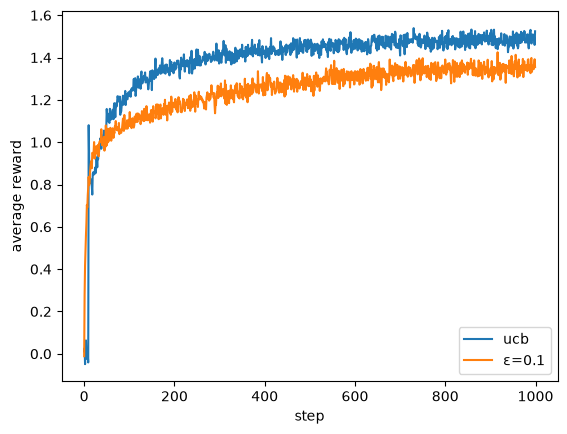

In [23]:
plt.plot(all_rewards_1.mean(axis=0), label="ucb")
plt.plot(all_rewards_2.mean(axis=0), label="ε=0.1")
plt.xlabel("step")
plt.ylabel("average reward")
plt.legend()
plt.show()

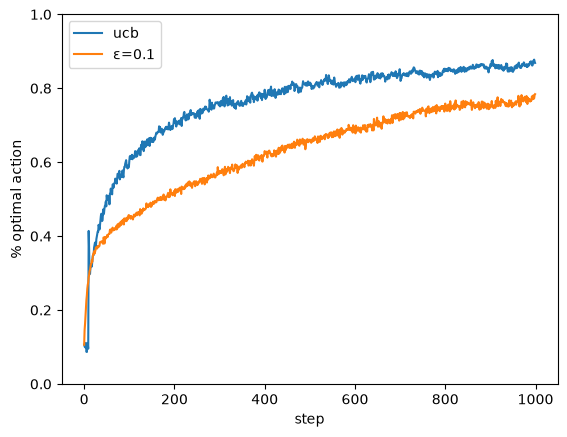

In [24]:
plt.plot(opt_1.mean(axis=0), label="ucb")
plt.plot(opt_2.mean(axis=0), label="ε=0.1")
plt.xlabel("step")
plt.ylabel("% optimal action")
plt.ylim(0, 1)
plt.legend()
plt.show()

# Gradient bandit (stochastic gradient ascent)

**Reminder.** Instead of estimating $Q(a)$, we learn **preferences** $H(a)$ and sample actions from a softmax (Boltzmann) policy:

$$\pi_t(a) = \frac{e^{H_t(a)}}{\sum_b e^{H_t(b)}}$$

Update (with baseline $\bar R_t$ = average reward so far):

$$
H_{t+1}(a) =
\begin{cases}
H_t(a) + \alpha (R_t - \bar R_t)(1-\pi_t(a)) & a = A_t \\
H_t(a) - \alpha (R_t - \bar R_t)\pi_t(a) & a \neq A_t
\end{cases}
$$

`use_baseline=True` uses $\bar R_t$ (course version); `False` replaces it by $0$ (ablation).

**What we do here.** Gradient bandit ($\alpha=0.1$, with baseline) vs $\varepsilon$-greedy on the stationary bandit.


In [25]:
class GradientBanditAgent(Agent):
    def __init__(self, bandit, alpha=0.1, use_baseline=True):
        super().__init__(bandit, bandit.n_arms)
        self.alpha = alpha
        self.use_baseline = use_baseline
        self.H = np.zeros(bandit.n_arms)
        self.avg_reward = 0.0
        self.t = 0

    def reset(self):
        super().reset()
        self.H = np.zeros(self.num_actions)
        self.avg_reward = 0.0
        self.t = 0

    def _softmax(self):
        # stable softmax
        z = self.H - np.max(self.H)
        exp_h = np.exp(z)
        return exp_h / np.sum(exp_h)

    def select_action(self):
        self.pi = self._softmax()
        return np.random.choice(self.num_actions, p=self.pi)

    def update(self, action, reward):
        self.t += 1
        baseline = self.avg_reward if self.use_baseline else 0.0

        one_hot = np.zeros(self.num_actions)
        one_hot[action] = 1.0
        self.H += self.alpha * (reward - baseline) * (one_hot - self.pi)

        if self.use_baseline:
            self.avg_reward += (reward - self.avg_reward) / self.t

In [26]:
n_runs, n_steps = 2000, 1000  
all_rewards_1 = np.zeros((n_runs, n_steps))
all_rewards_2 = np.zeros((n_runs, n_steps))

opt_1 = np.zeros((n_runs, n_steps))
opt_2 = np.zeros((n_runs, n_steps))

for run in range(n_runs):
    bandit = Bandit()
    agent_1 = GradientBanditAgent(bandit, alpha=0.1, use_baseline=True)
    agent_1.run(n_steps)
    all_rewards_1[run] = agent_1.rewards
    opt_1[run] = agent_1.optimal_actions

    agent_2 = IncrementalUpdateAgent(bandit, epsilon=0.1, alpha=0.1)
    agent_2.run(n_steps)
    all_rewards_2[run] = agent_2.rewards
    opt_2[run] = agent_2.optimal_actions

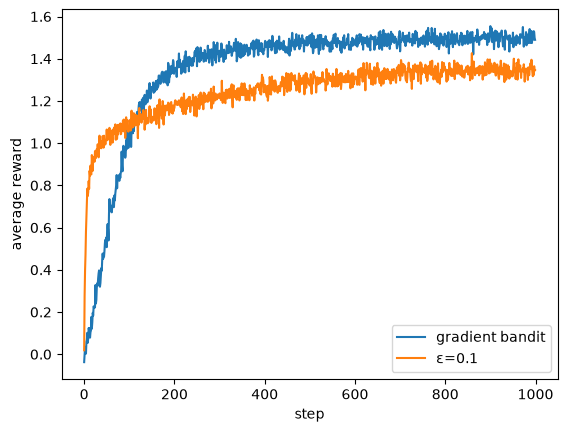

In [27]:
plt.plot(all_rewards_1.mean(axis=0), label="gradient bandit")
plt.plot(all_rewards_2.mean(axis=0), label="ε=0.1")
plt.xlabel("step")
plt.ylabel("average reward")
plt.legend()
plt.show()

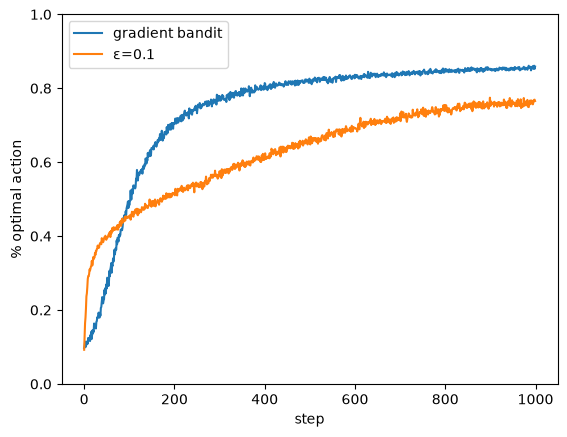

In [28]:
plt.plot(opt_1.mean(axis=0), label="gradient bandit")
plt.plot(opt_2.mean(axis=0), label="ε=0.1")
plt.xlabel("step")
plt.ylabel("% optimal action")
plt.ylim(0, 1)
plt.legend()
plt.show()

## References

1. S. Airiau. *Apprentissage par renforcement*. M2 IASD, Université Paris Dauphine. Lecture 1: *Introduction et problème des bandits manchots*. [https://www.lamsade.dauphine.fr/~airiau/Teaching/M2-IASDapp-RL/](https://www.lamsade.dauphine.fr/~airiau/Teaching/M2-IASDapp-RL/)
